In [618]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,accuracy_score
from  sklearn.naive_bayes import GaussianNB,BernoulliNB

# Load data

In [619]:
df =  pd.read_csv('/content/loan_train.csv')
df.head(10)

,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History,Area,Status
0,Male,No,0,Graduate,No,584900,0.0,15000000,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,458300,150800.0,12800000,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,300000,0.0,6600000,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,258300,235800.0,12000000,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,600000,0.0,14100000,360.0,1.0,Urban,Y
5,Male,Yes,2,Graduate,Yes,541700,419600.0,26700000,360.0,1.0,Urban,Y
6,Male,Yes,0,Not Graduate,No,233300,151600.0,9500000,360.0,1.0,Urban,Y
7,Male,Yes,3+,Graduate,No,303600,250400.0,15800000,360.0,0.0,Semiurban,N
8,Male,Yes,2,Graduate,No,400600,152600.0,16800000,360.0,1.0,Urban,Y
9,Male,Yes,1,Graduate,No,1284100,1096800.0,34900000,360.0,1.0,Semiurban,N


#Data Properties

In [620]:
df.shape

(614, 12)

In [621]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Term',
       'Credit_History', 'Area', 'Status'],
      dtype='object')

In [622]:
df.dtypes

,0
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
Applicant_Income,int64
Coapplicant_Income,float64
Loan_Amount,int64
Term,float64
Credit_History,float64


In [623]:
df.describe()

,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History
count,6.140000e+02,6.140000e+02,6.140000e+02,600.00000,564.000000
mean,5.403459e+05,1.621246e+05,1.414104e+07,342.00000,0.842199
std,6.109042e+05,2.926248e+05,8.815682e+06,65.12041,0.364878
min,1.500000e+04,0.000000e+00,0.000000e+00,12.00000,0.000000
25%,2.877500e+05,0.000000e+00,9.800000e+06,360.00000,1.000000
50%,3.812500e+05,1.188500e+05,1.250000e+07,360.00000,1.000000
75%,5.795000e+05,2.297250e+05,1.647500e+07,360.00000,1.000000
max,8.100000e+06,4.166700e+06,7.000000e+07,480.00000,1.000000


In [624]:
df.isna().sum()

,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
Applicant_Income,0
Coapplicant_Income,0
Loan_Amount,0
Term,14
Credit_History,50


# Data Visualisataiom

## Gender wise

<Axes: xlabel='Status', ylabel='count'>

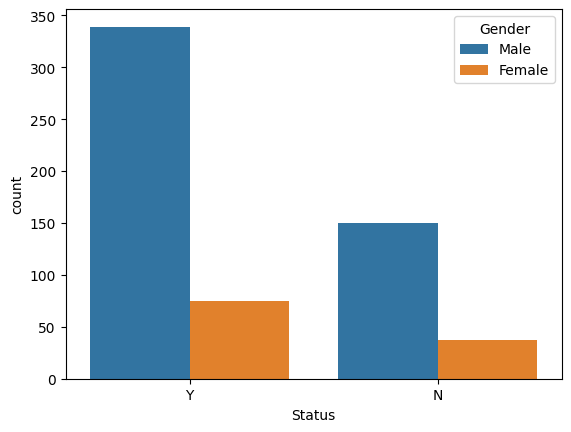

In [625]:
sns.countplot(data=df,x='Status',hue='Gender')

<Axes: xlabel='Status', ylabel='count'>

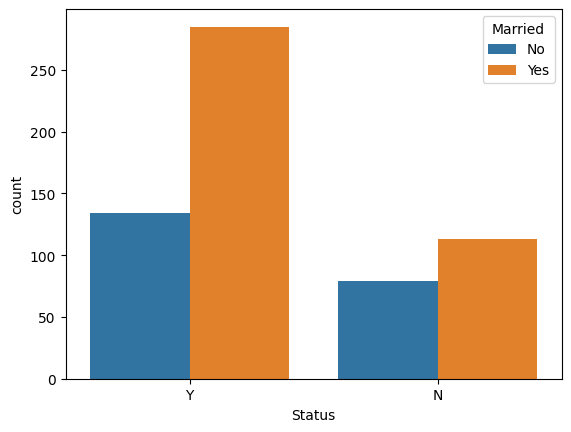

In [626]:
sns.countplot(data=df,x='Status',hue='Married')

<Axes: xlabel='Status', ylabel='count'>

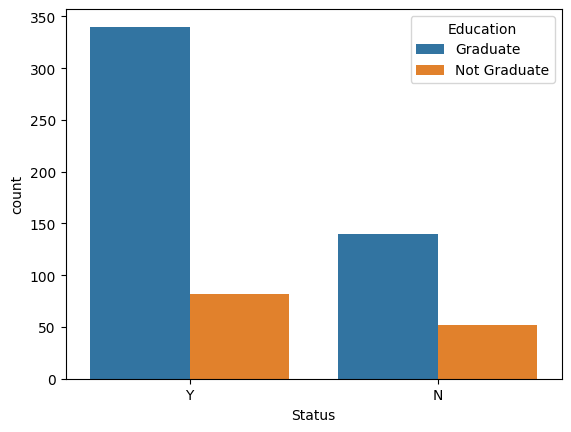

In [627]:
sns.countplot(data=df,x='Status',hue='Education')

<Axes: xlabel='Status', ylabel='count'>

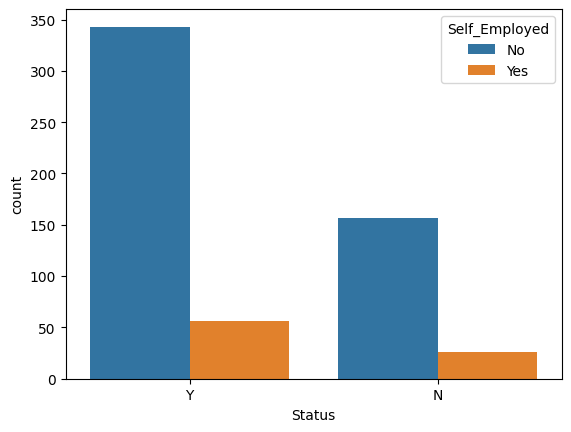

In [628]:
sns.countplot(data=df,x='Status',hue='Self_Employed')

<Axes: xlabel='Status', ylabel='count'>

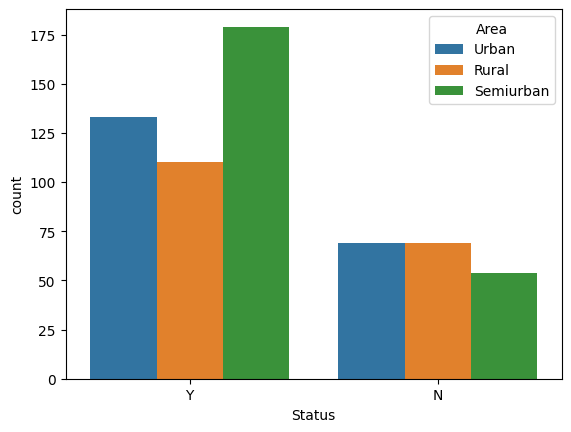

In [629]:
sns.countplot(data=df,x='Status',hue='Area')

# Handle Missing Values

In [630]:
df['Gender'].unique()

array(['Male', 'Female', nan], dtype=object)

In [631]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [632]:
df['Married'].unique()

array(['No', 'Yes', nan], dtype=object)

In [633]:
df['Married'] = df["Married"].fillna(df["Married"].mode()[0])

In [634]:
df['Dependents'].unique()

array(['0', '1', '2', '3+', nan], dtype=object)

In [635]:
df['Dependents'].replace('3+','3',inplace=True)

/tmp/ipykernel_8351/2995779663.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Dependents'].replace('3+','3',inplace=True)


In [636]:
df['Dependents'] = pd.to_numeric(df['Dependents'])

In [637]:
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].mode()[0])

In [638]:
df['Dependents'] = df['Dependents'].astype(int)

In [639]:
df['Self_Employed'].unique()

array(['No', 'Yes', nan], dtype=object)

In [640]:
df['Self_Employed'] = df['Gender'].fillna(df['Self_Employed'].mode()[0])

In [641]:
df['Term'].unique()

array([360., 120., 240.,  nan, 180.,  60., 300., 480.,  36.,  84.,  12.])

In [642]:
df['Term'] = df['Term'].fillna(df['Term'].median())

In [643]:
# df['Term']

In [644]:
df['Credit_History'].unique()

array([ 1.,  0., nan])

In [645]:
df['Credit_History']=df['Credit_History'].fillna(df['Credit_History'].mode()[0])

In [646]:
df.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
Applicant_Income,0
Coapplicant_Income,0
Loan_Amount,0
Term,0
Credit_History,0


# Encoding

In [647]:
lab = LabelEncoder()
df['Gender'] = lab.fit_transform(df['Gender'])
df['Married'] = lab.fit_transform(df['Married'])
df['Education'] = lab.fit_transform(df['Education'])
df['Self_Employed'] = lab.fit_transform(df['Self_Employed'])
df['Area'] = lab.fit_transform(df['Area'])

In [648]:
df.head(10)

,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History,Area,Status
0,1,0,0,0,1,584900,0.0,15000000,360.0,1.0,2,Y
1,1,1,1,0,1,458300,150800.0,12800000,360.0,1.0,0,N
2,1,1,0,0,1,300000,0.0,6600000,360.0,1.0,2,Y
3,1,1,0,1,1,258300,235800.0,12000000,360.0,1.0,2,Y
4,1,0,0,0,1,600000,0.0,14100000,360.0,1.0,2,Y
5,1,1,2,0,1,541700,419600.0,26700000,360.0,1.0,2,Y
6,1,1,0,1,1,233300,151600.0,9500000,360.0,1.0,2,Y
7,1,1,3,0,1,303600,250400.0,15800000,360.0,0.0,1,N
8,1,1,2,0,1,400600,152600.0,16800000,360.0,1.0,2,Y
9,1,1,1,0,1,1284100,1096800.0,34900000,360.0,1.0,1,N


In [649]:
df.dtypes

,0
Gender,int64
Married,int64
Dependents,int64
Education,int64
Self_Employed,int64
Applicant_Income,int64
Coapplicant_Income,float64
Loan_Amount,int64
Term,float64
Credit_History,float64


In [650]:
x= df.iloc[:,:-1]
y=df.iloc[:,-1]

## Scaling

In [651]:
scaler = StandardScaler()
scaler.fit(x)
x = scaler.transform(x)

## Test Tarin split

In [652]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.33,random_state=42)

# Model Building


In [653]:
model = BernoulliNB()
model.fit(x_train,y_train)

BernoulliNB()

In [654]:
y_pred = model.predict(x_test)

 # Accuracy Score

In [655]:
score = accuracy_score(y_test,y_pred)
score

0.7980295566502463